# Dataset Loading and Preprocessing then combining

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
df = pd.read_csv('phishing_data/mixed_phishing_urls.csv')

In [3]:
df.head()

,URL,Label
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,bad
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,bad
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,bad
3,mail.printakid.com/www.online.americanexpress....,bad
4,thewhiskeydregs.com/wp-content/themes/widescre...,bad


In [4]:
df.shape

(549346, 2)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 549346 entries, 0 to 549345
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   URL     549346 non-null  object
 1   Label   549346 non-null  object
dtypes: object(2)
memory usage: 8.4+ MB


In [6]:
df.isnull().sum()

URL      0
Label    0
dtype: int64

In [7]:
df.Label.value_counts() * (100/549346)

Label
good    71.525778
bad     28.474222
Name: count, dtype: float64

In [8]:
from nltk.tokenize import RegexpTokenizer

In [9]:
tokenizer = RegexpTokenizer(r'[A-Za-z]+')

In [10]:
df.URL[0]

'nobell.it/70ffb52d079109dca5664cce6f317373782/login.SkyPe.com/en/cgi-bin/verification/login/70ffb52d079109dca5664cce6f317373/index.php?cmd=_profile-ach&outdated_page_tmpl=p/gen/failed-to-load&nav=0.5.1&login_access=1322408526'

In [11]:
tokenizer.tokenize(df.URL[0])

['nobell',
 'it',
 'ffb',
 'd',
 'dca',
 'cce',
 'f',
 'login',
 'SkyPe',
 'com',
 'en',
 'cgi',
 'bin',
 'verification',
 'login',
 'ffb',
 'd',
 'dca',
 'cce',
 'f',
 'index',
 'php',
 'cmd',
 'profile',
 'ach',
 'outdated',
 'page',
 'tmpl',
 'p',
 'gen',
 'failed',
 'to',
 'load',
 'nav',
 'login',
 'access']

In [12]:
df['tokenized_text'] = df.URL.map(lambda t: tokenizer.tokenize(t))

In [13]:
df.head()

,URL,Label,tokenized_text
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,bad,"[nobell, it, ffb, d, dca, cce, f, login, SkyPe..."
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,bad,"[www, dghjdgf, com, paypal, co, uk, cycgi, bin..."
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,bad,"[serviciosbys, com, paypal, cgi, bin, get, int..."
3,mail.printakid.com/www.online.americanexpress....,bad,"[mail, printakid, com, www, online, americanex..."
4,thewhiskeydregs.com/wp-content/themes/widescre...,bad,"[thewhiskeydregs, com, wp, content, themes, wi..."


In [14]:
from nltk.stem.snowball import SnowballStemmer

In [15]:
stemmer = SnowballStemmer('english')

In [16]:
df['stemmed_text'] = df['tokenized_text'].map(lambda l: [stemmer.stem(word) for word in l])

In [17]:
df.head()

,URL,Label,tokenized_text,stemmed_text
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,bad,"[nobell, it, ffb, d, dca, cce, f, login, SkyPe...","[nobel, it, ffb, d, dca, cce, f, login, skype,..."
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,bad,"[www, dghjdgf, com, paypal, co, uk, cycgi, bin...","[www, dghjdgf, com, paypal, co, uk, cycgi, bin..."
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,bad,"[serviciosbys, com, paypal, cgi, bin, get, int...","[serviciosbi, com, paypal, cgi, bin, get, into..."
3,mail.printakid.com/www.online.americanexpress....,bad,"[mail, printakid, com, www, online, americanex...","[mail, printakid, com, www, onlin, americanexp..."
4,thewhiskeydregs.com/wp-content/themes/widescre...,bad,"[thewhiskeydregs, com, wp, content, themes, wi...","[thewhiskeydreg, com, wp, content, theme, wide..."


In [18]:
df['text'] = df['stemmed_text'].map(lambda l: ' '.join(l))

In [19]:
df.head()

,URL,Label,tokenized_text,stemmed_text,text
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,bad,"[nobell, it, ffb, d, dca, cce, f, login, SkyPe...","[nobel, it, ffb, d, dca, cce, f, login, skype,...",nobel it ffb d dca cce f login skype com en cg...
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,bad,"[www, dghjdgf, com, paypal, co, uk, cycgi, bin...","[www, dghjdgf, com, paypal, co, uk, cycgi, bin...",www dghjdgf com paypal co uk cycgi bin webscrc...
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,bad,"[serviciosbys, com, paypal, cgi, bin, get, int...","[serviciosbi, com, paypal, cgi, bin, get, into...",serviciosbi com paypal cgi bin get into herf s...
3,mail.printakid.com/www.online.americanexpress....,bad,"[mail, printakid, com, www, online, americanex...","[mail, printakid, com, www, onlin, americanexp...",mail printakid com www onlin americanexpress c...
4,thewhiskeydregs.com/wp-content/themes/widescre...,bad,"[thewhiskeydregs, com, wp, content, themes, wi...","[thewhiskeydreg, com, wp, content, theme, wide...",thewhiskeydreg com wp content theme widescreen...


In [20]:
df1 = pd.read_csv("phishing_data/phishtank_phishing_urls.csv")

In [21]:
df1.head()

,phish_id,url,phish_detail_url,submission_time,verified,verification_time,online,target
0,9536109,https://novobanco.novoalerta.com/,http://www.phishtank.com/phish_detail.php?phis...,2026-10-01T15:05:37+00:00,yes,2026-10-01T15:11:36+00:00,yes,Other
1,9536053,https://att-sign-in-1c41ac.webflow.io/,http://www.phishtank.com/phish_detail.php?phis...,2026-10-01T14:01:16+00:00,yes,2026-10-01T14:21:28+00:00,yes,Other
2,9535971,https://reurl.cc/qa4krD,http://www.phishtank.com/phish_detail.php?phis...,2026-10-01T13:25:02+00:00,yes,2026-10-01T13:31:45+00:00,yes,Other
3,9535961,https://bellsouth-verifier-sign-in-17cc27.webf...,http://www.phishtank.com/phish_detail.php?phis...,2026-10-01T13:11:27+00:00,yes,2026-10-01T13:21:13+00:00,yes,Other
4,9535957,https://redcxtoon.serviceopoziulfmpztarhjppl.s...,http://www.phishtank.com/phish_detail.php?phis...,2026-10-01T13:07:08+00:00,yes,2026-10-01T13:11:37+00:00,yes,Other


In [22]:
df1.shape

(76660, 8)

In [23]:
df1 = df1.drop(columns = ["phish_id", "phish_detail_url", "submission_time", "verified", "verification_time", "online", "target"], axis = 1)

In [24]:
df1.head()

,url
0,https://novobanco.novoalerta.com/
1,https://att-sign-in-1c41ac.webflow.io/
2,https://reurl.cc/qa4krD
3,https://bellsouth-verifier-sign-in-17cc27.webf...
4,https://redcxtoon.serviceopoziulfmpztarhjppl.s...


In [25]:
df1["Label"] = "bad"

In [26]:
df1.rename(columns={"url": "URL"}, inplace=True)

In [27]:
df1.head()

,URL,Label
0,https://novobanco.novoalerta.com/,bad
1,https://att-sign-in-1c41ac.webflow.io/,bad
2,https://reurl.cc/qa4krD,bad
3,https://bellsouth-verifier-sign-in-17cc27.webf...,bad
4,https://redcxtoon.serviceopoziulfmpztarhjppl.s...,bad


In [28]:
df1.Label.value_counts()

Label
bad    76660
Name: count, dtype: int64

In [29]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76660 entries, 0 to 76659
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   URL     76660 non-null  object
 1   Label   76660 non-null  object
dtypes: object(2)
memory usage: 1.2+ MB


In [30]:
df1.isnull().sum()

URL      0
Label    0
dtype: int64

In [31]:
df1.duplicated().sum()

3

In [32]:
df1.drop_duplicates(inplace=True)

In [33]:
df1.duplicated().sum()

0

In [34]:
df1['tokenized_text'] = df1.URL.map(lambda t: tokenizer.tokenize(t))

In [35]:
df1.head()

,URL,Label,tokenized_text
0,https://novobanco.novoalerta.com/,bad,"[https, novobanco, novoalerta, com]"
1,https://att-sign-in-1c41ac.webflow.io/,bad,"[https, att, sign, in, c, ac, webflow, io]"
2,https://reurl.cc/qa4krD,bad,"[https, reurl, cc, qa, krD]"
3,https://bellsouth-verifier-sign-in-17cc27.webf...,bad,"[https, bellsouth, verifier, sign, in, cc, web..."
4,https://redcxtoon.serviceopoziulfmpztarhjppl.s...,bad,"[https, redcxtoon, serviceopoziulfmpztarhjppl,..."


In [36]:
df1['stemmed_text'] = df1['tokenized_text'].map(lambda l: [stemmer.stem(word) for word in l])

In [37]:
df1.head()

,URL,Label,tokenized_text,stemmed_text
0,https://novobanco.novoalerta.com/,bad,"[https, novobanco, novoalerta, com]","[https, novobanco, novoalerta, com]"
1,https://att-sign-in-1c41ac.webflow.io/,bad,"[https, att, sign, in, c, ac, webflow, io]","[https, att, sign, in, c, ac, webflow, io]"
2,https://reurl.cc/qa4krD,bad,"[https, reurl, cc, qa, krD]","[https, reurl, cc, qa, krd]"
3,https://bellsouth-verifier-sign-in-17cc27.webf...,bad,"[https, bellsouth, verifier, sign, in, cc, web...","[https, bellsouth, verifi, sign, in, cc, webfl..."
4,https://redcxtoon.serviceopoziulfmpztarhjppl.s...,bad,"[https, redcxtoon, serviceopoziulfmpztarhjppl,...","[https, redcxtoon, serviceopoziulfmpztarhjppl,..."


In [38]:
df1['text'] = df1['stemmed_text'].map(lambda l: ' '.join(l))

In [39]:
df1.head()

,URL,Label,tokenized_text,stemmed_text,text
0,https://novobanco.novoalerta.com/,bad,"[https, novobanco, novoalerta, com]","[https, novobanco, novoalerta, com]",https novobanco novoalerta com
1,https://att-sign-in-1c41ac.webflow.io/,bad,"[https, att, sign, in, c, ac, webflow, io]","[https, att, sign, in, c, ac, webflow, io]",https att sign in c ac webflow io
2,https://reurl.cc/qa4krD,bad,"[https, reurl, cc, qa, krD]","[https, reurl, cc, qa, krd]",https reurl cc qa krd
3,https://bellsouth-verifier-sign-in-17cc27.webf...,bad,"[https, bellsouth, verifier, sign, in, cc, web...","[https, bellsouth, verifi, sign, in, cc, webfl...",https bellsouth verifi sign in cc webflow io
4,https://redcxtoon.serviceopoziulfmpztarhjppl.s...,bad,"[https, redcxtoon, serviceopoziulfmpztarhjppl,...","[https, redcxtoon, serviceopoziulfmpztarhjppl,...",https redcxtoon serviceopoziulfmpztarhjppl sbs...


In [40]:
df.head()

,URL,Label,tokenized_text,stemmed_text,text
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,bad,"[nobell, it, ffb, d, dca, cce, f, login, SkyPe...","[nobel, it, ffb, d, dca, cce, f, login, skype,...",nobel it ffb d dca cce f login skype com en cg...
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,bad,"[www, dghjdgf, com, paypal, co, uk, cycgi, bin...","[www, dghjdgf, com, paypal, co, uk, cycgi, bin...",www dghjdgf com paypal co uk cycgi bin webscrc...
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,bad,"[serviciosbys, com, paypal, cgi, bin, get, int...","[serviciosbi, com, paypal, cgi, bin, get, into...",serviciosbi com paypal cgi bin get into herf s...
3,mail.printakid.com/www.online.americanexpress....,bad,"[mail, printakid, com, www, online, americanex...","[mail, printakid, com, www, onlin, americanexp...",mail printakid com www onlin americanexpress c...
4,thewhiskeydregs.com/wp-content/themes/widescre...,bad,"[thewhiskeydregs, com, wp, content, themes, wi...","[thewhiskeydreg, com, wp, content, theme, wide...",thewhiskeydreg com wp content theme widescreen...


In [41]:
new_df = pd.concat([df, df1], ignore_index=True)

In [42]:
new_df.sample(5)

,URL,Label,tokenized_text,stemmed_text,text
440852,superpages.com/bp/Springfield-IL/Penny-Lane-L0...,good,"[superpages, com, bp, Springfield, IL, Penny, ...","[superpag, com, bp, springfield, il, penni, la...",superpag com bp springfield il penni lane l htm
20246,www.devaworld.com/leela/home/cgibin/nl/qibdred...,bad,"[www, devaworld, com, leela, home, cgibin, nl,...","[www, devaworld, com, leela, home, cgibin, nl,...",www devaworld com leela home cgibin nl qibdred...
423979,robertsvideos.com/browse.php3?All=&keywords=&N...,good,"[robertsvideos, com, browse, php, All, keyword...","[robertsvideo, com, brows, php, all, keyword, ...",robertsvideo com brows php all keyword npal me...
601335,https://campsite.bio/myattaccount,bad,"[https, campsite, bio, myattaccount]","[https, campsit, bio, myattaccount]",https campsit bio myattaccount
172473,en.wikipedia.org/wiki/Category:American_dance_...,good,"[en, wikipedia, org, wiki, Category, American,...","[en, wikipedia, org, wiki, categori, american,...",en wikipedia org wiki categori american danc film


In [43]:
new_df.shape

(626003, 5)

In [44]:
new_df.isnull().sum()

URL               0
Label             0
tokenized_text    0
stemmed_text      0
text              0
dtype: int64

In [45]:
new_df.drop_duplicates(subset=["URL"], inplace=True)
new_df.reset_index(drop=True, inplace=True)

In [46]:
new_df.shape

(583852, 5)

In [47]:
df.shape

(549346, 5)

In [48]:
df2 = pd.read_csv("phishing_data/openphish_phishing_urls.csv")

In [49]:
df2.sample(5)

,URL,Label
160,http://www.ondemand-app-tour.vercel.app/,phishing
219,https://www.roblox.com.mu/users/5900172182/pro...,phishing
64,https://vhxm.stargazer.rest/xuve/,phishing
154,https://fseryy.pages.dev/SuperATV-Windshield-R...,phishing
178,https://insight-information-digest.s2498700.wo...,phishing


In [50]:
df2.shape

(300, 2)

In [51]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   URL     300 non-null    object
 1   Label   300 non-null    object
dtypes: object(2)
memory usage: 4.8+ KB


In [52]:
df2.duplicated().sum()

0

In [53]:
df2["Label"] = df2["Label"].replace("phishing", "bad")

In [54]:
df2.head()

,URL,Label
0,https://webmail-ionos-auth-app-suite-didactic-...,bad
1,https://sendbscusdtbnb.vercel.app/,bad
2,https://ka-importexportmicroframework.vercel.app/,bad
3,http://www.ka-importexportmicroframework.verce...,bad
4,https://www.xhwdone.xyz/,bad


In [55]:
df2['tokenized_text'] = df2.URL.map(lambda t: tokenizer.tokenize(t))

In [56]:
df2['stemmed_text'] = df2['tokenized_text'].map(lambda l: [stemmer.stem(word) for word in l])
df2['text'] = df2['stemmed_text'].map(lambda l: ' '.join(l))

In [57]:
df2.head()

,URL,Label,tokenized_text,stemmed_text,text
0,https://webmail-ionos-auth-app-suite-didactic-...,bad,"[https, webmail, ionos, auth, app, suite, dida...","[https, webmail, iono, auth, app, suit, didact...",https webmail iono auth app suit didact carniv...
1,https://sendbscusdtbnb.vercel.app/,bad,"[https, sendbscusdtbnb, vercel, app]","[https, sendbscusdtbnb, vercel, app]",https sendbscusdtbnb vercel app
2,https://ka-importexportmicroframework.vercel.app/,bad,"[https, ka, importexportmicroframework, vercel...","[https, ka, importexportmicroframework, vercel...",https ka importexportmicroframework vercel app
3,http://www.ka-importexportmicroframework.verce...,bad,"[http, www, ka, importexportmicroframework, ve...","[http, www, ka, importexportmicroframework, ve...",http www ka importexportmicroframework vercel app
4,https://www.xhwdone.xyz/,bad,"[https, www, xhwdone, xyz]","[https, www, xhwdone, xyz]",https www xhwdone xyz


In [58]:
new_df1 = pd.concat([new_df, df2], ignore_index=True)

In [59]:
new_df1.shape

(584152, 5)

In [60]:
new_df1.sample(5)

,URL,Label,tokenized_text,stemmed_text,text
428359,sortiesjazznights.com/2/Left_menu/Jazzonthenet,good,"[sortiesjazznights, com, Left, menu, Jazzonthe...","[sortiesjazznight, com, left, menu, jazzonthenet]",sortiesjazznight com left menu jazzonthenet
272617,amebc.ca/Home.aspx,good,"[amebc, ca, Home, aspx]","[amebc, ca, home, aspx]",amebc ca home aspx
241061,thelowell50.com/,good,"[thelowell, com]","[thelowel, com]",thelowel com
98497,andisukiboutique.com/confirm1/ac/websc-login.php,bad,"[andisukiboutique, com, confirm, ac, websc, lo...","[andisukiboutiqu, com, confirm, ac, websc, log...",andisukiboutiqu com confirm ac websc login php
412648,publishersglobal.com/directory/publisher.asp?p...,good,"[publishersglobal, com, directory, publisher, ...","[publishersglob, com, directori, publish, asp,...",publishersglob com directori publish asp publi...


In [61]:
new_df1.drop_duplicates(subset=["URL"], inplace=True)
new_df1.reset_index(drop=True, inplace=True)

In [62]:
new_df1.shape

(584150, 5)

In [63]:
new_df1.isnull().sum()

URL               0
Label             0
tokenized_text    0
stemmed_text      0
text              0
dtype: int64

In [64]:
df3 = pd.read_csv("phishing_data/tranco_phishing_urls.csv")

In [65]:
df3.shape

(999999, 2)

In [66]:
new_df1.Label.value_counts()

Label
good    392897
bad     191253
Name: count, dtype: int64

In [67]:
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 999999 entries, 0 to 999998
Data columns (total 2 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   1           999999 non-null  int64 
 1   google.com  999999 non-null  object
dtypes: int64(1), object(1)
memory usage: 15.3+ MB


In [68]:
df3.isnull().sum()

1             0
google.com    0
dtype: int64

In [69]:
df3.head()

,1,google.com
0,2,cloudflare.com
1,3,facebook.com
2,4,gstatic.com
3,5,amazonaws.com
4,6,googleapis.com


In [70]:
df3.rename(columns={"google.com": "URL"}, inplace=True)

In [71]:
df3.head()

,1,URL
0,2,cloudflare.com
1,3,facebook.com
2,4,gstatic.com
3,5,amazonaws.com
4,6,googleapis.com


In [72]:
new_df1.head()

,URL,Label,tokenized_text,stemmed_text,text
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,bad,"[nobell, it, ffb, d, dca, cce, f, login, SkyPe...","[nobel, it, ffb, d, dca, cce, f, login, skype,...",nobel it ffb d dca cce f login skype com en cg...
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,bad,"[www, dghjdgf, com, paypal, co, uk, cycgi, bin...","[www, dghjdgf, com, paypal, co, uk, cycgi, bin...",www dghjdgf com paypal co uk cycgi bin webscrc...
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,bad,"[serviciosbys, com, paypal, cgi, bin, get, int...","[serviciosbi, com, paypal, cgi, bin, get, into...",serviciosbi com paypal cgi bin get into herf s...
3,mail.printakid.com/www.online.americanexpress....,bad,"[mail, printakid, com, www, online, americanex...","[mail, printakid, com, www, onlin, americanexp...",mail printakid com www onlin americanexpress c...
4,thewhiskeydregs.com/wp-content/themes/widescre...,bad,"[thewhiskeydregs, com, wp, content, themes, wi...","[thewhiskeydreg, com, wp, content, theme, wide...",thewhiskeydreg com wp content theme widescreen...


In [73]:
new_df1.shape

(584150, 5)

In [74]:
good_sites = new_df1[new_df1.Label == 'good']
bad_sites = new_df1[new_df1.Label == 'bad']

In [75]:
good_sites.head()

,URL,Label,tokenized_text,stemmed_text,text
18231,esxcc.com/js/index.htm?us.battle.net/noghn/en/...,good,"[esxcc, com, js, index, htm, us, battle, net, ...","[esxcc, com, js, index, htm, us, battl, net, n...",esxcc com js index htm us battl net noghn en r...
18232,wwweira¯&nvinip¿ncH¯wVö%ÆåyDaHðû/ÏyEùuË\nÓ6...,good,"[www, eira, nvinip, ncH, wV, yDaH, yE, u, rT, ...","[www, eira, nvinip, nch, wv, ydah, ye, u, rt, ...",www eira nvinip nch wv ydah ye u rt u g m i xz...
18233,'www.institutocgr.coo/web/media/syqvem/dk-óij...,good,"[www, institutocgr, coo, web, media, syqvem, d...","[www, institutocgr, coo, web, media, syqvem, d...",www institutocgr coo web media syqvem dk ij r ...
18234,Yìê koãÕ»Î§DéÎl½ñ¡ââqtò¸/à; Í,good,"[Y, ko, D, l, qt]","[y, ko, d, l, qt]",y ko d l qt
18236,ruta89fm.com/images/AS@Vies/1i75cf7b16vc<Fd16...,good,"[ruta, fm, com, images, AS, Vies, i, cf, b, vc...","[ruta, fm, com, imag, as, vie, i, cf, b, vc, f...",ruta fm com imag as vie i cf b vc f d b g sd v...


In [76]:
bad_sites.head()

,URL,Label,tokenized_text,stemmed_text,text
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,bad,"[nobell, it, ffb, d, dca, cce, f, login, SkyPe...","[nobel, it, ffb, d, dca, cce, f, login, skype,...",nobel it ffb d dca cce f login skype com en cg...
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,bad,"[www, dghjdgf, com, paypal, co, uk, cycgi, bin...","[www, dghjdgf, com, paypal, co, uk, cycgi, bin...",www dghjdgf com paypal co uk cycgi bin webscrc...
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,bad,"[serviciosbys, com, paypal, cgi, bin, get, int...","[serviciosbi, com, paypal, cgi, bin, get, into...",serviciosbi com paypal cgi bin get into herf s...
3,mail.printakid.com/www.online.americanexpress....,bad,"[mail, printakid, com, www, online, americanex...","[mail, printakid, com, www, onlin, americanexp...",mail printakid com www onlin americanexpress c...
4,thewhiskeydregs.com/wp-content/themes/widescre...,bad,"[thewhiskeydregs, com, wp, content, themes, wi...","[thewhiskeydreg, com, wp, content, theme, wide...",thewhiskeydreg com wp content theme widescreen...


In [79]:
def plot_wordcloud(text, mask=None, max_words=400, max_font_size=120, figure_size=(24.0,16.0), 
                   title = None, title_size=40, image_color=False):
    stopwords = set(STOPWORDS)
    more_stopwords = {'com','http'}
    stopwords = stopwords.union(more_stopwords)

    wordcloud = WordCloud(background_color='white',
                    stopwords = stopwords,
                    max_words = max_words,
                    max_font_size = max_font_size, 
                    random_state = 42,
                    mask = mask)
    wordcloud.generate(text)
    
    plt.figure(figsize=figure_size)
    if image_color:
        image_colors = ImageColorGenerator(mask);
        plt.imshow(wordcloud.recolor(color_func=image_colors), interpolation="bilinear");
        plt.title(title, fontdict={'size': title_size,  
                                  'verticalalignment': 'bottom'})
    else:
        plt.imshow(wordcloud);
        plt.title(title, fontdict={'size': title_size, 'color': 'green', 
                                  'verticalalignment': 'bottom'})
    plt.axis('off');
    plt.tight_layout() 

In [80]:
all_text = ' '.join(good_sites['text'].tolist())

In [81]:
from wordcloud import WordCloud

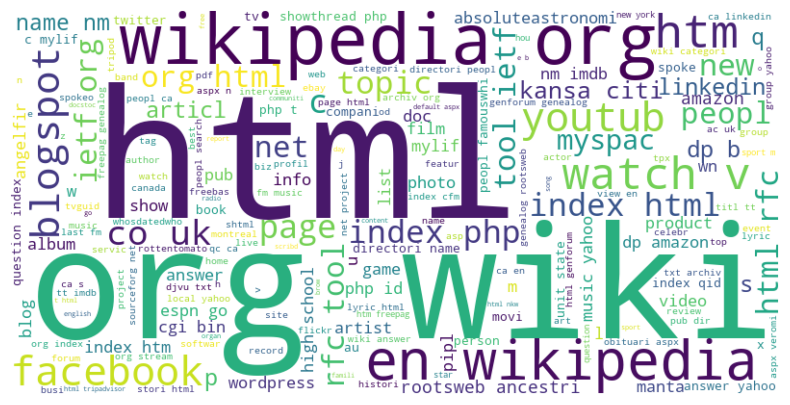

In [82]:
# Generate word cloud
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(all_text)

# Display the word cloud
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

In [83]:
all_text= ' '.join(bad_sites['text'].tolist())

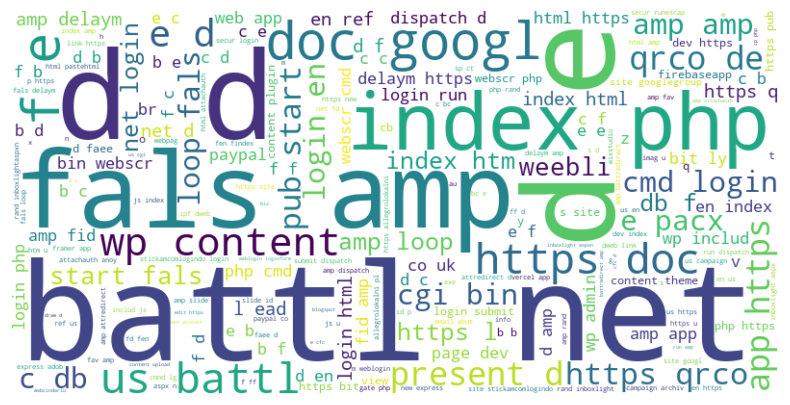

In [84]:
# Generate word cloud
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(all_text)

# Display the word cloud
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

# Model Training and Testing

In [77]:
from sklearn.feature_extraction.text import CountVectorizer

In [78]:
cv = CountVectorizer()

In [79]:
features = cv.fit_transform(new_df1.text)

In [80]:
features[:5].toarray()

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=int64)

In [81]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [82]:
X = features
y = new_df1["Label"]
y.value_counts()

Label
good    392897
bad     191253
Name: count, dtype: int64

In [83]:
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42,stratify=y)

In [84]:
X_train.shape

(467320, 448098)

In [85]:
X_test.shape

(116830, 448098)

In [86]:
def evaluate_model(y_test, y_pred):
    print("Accuracy :", accuracy_score(y_test, y_pred))
    
    print("Precision:", precision_score(y_test, y_pred, average="weighted", zero_division=0))
    
    print("Recall   :", recall_score(y_test, y_pred, average="weighted", zero_division=0))
    
    print("F1-Score :", f1_score(y_test, y_pred, average="weighted", zero_division=0))

    print("\nClassification Report:\n")
    print(classification_report(y_test, y_pred, zero_division=0))

    print("Confusion Matrix:\n")
    print(confusion_matrix(y_test, y_pred))

In [87]:
# Logistic Regression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

evaluate_model(y_test, y_pred_lr)

Accuracy : 0.9667979114953351
Precision: 0.967163520126356
Recall   : 0.9667979114953351
F1-Score : 0.9665116196872662

Classification Report:

              precision    recall  f1-score   support

         bad       0.98      0.92      0.95     38251
        good       0.96      0.99      0.98     78579

    accuracy                           0.97    116830
   macro avg       0.97      0.95      0.96    116830
weighted avg       0.97      0.97      0.97    116830

Confusion Matrix:

[[35118  3133]
 [  746 77833]]


In [88]:
print("Training Accuracy :", lr_model.score(X_train, y_train))
print("Testing Accuracy :", lr_model.score(X_test, y_test))

Training Accuracy : 0.9792497646152529
Testing Accuracy : 0.9667979114953351


In [89]:
# Decision tree Classifier

dt_model = DecisionTreeClassifier(random_state = 42)

dt_model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [90]:
y_pred_dt = dt_model.predict(X_test)

evaluate_model(y_test, y_pred_dt)

Accuracy : 0.9623127621330138
Precision: 0.962207773041111
Recall   : 0.9623127621330138
F1-Score : 0.9622022771719281

Classification Report:

              precision    recall  f1-score   support

         bad       0.95      0.93      0.94     38251
        good       0.97      0.98      0.97     78579

    accuracy                           0.96    116830
   macro avg       0.96      0.95      0.96    116830
weighted avg       0.96      0.96      0.96    116830

Confusion Matrix:

[[35624  2627]
 [ 1776 76803]]


In [91]:
print("Training Accuracy :", dt_model.score(X_train, y_train))
print("Testing Accuracy :", dt_model.score(X_test, y_test))

Training Accuracy : 0.9999186852691946
Testing Accuracy : 0.9623127621330138


In [92]:
# Multinomial Naive Bayes

mnb_model = MultinomialNB()

mnb_model.fit(X_train, y_train)

y_pred_mnb = mnb_model.predict(X_test)

evaluate_model(y_test, y_pred_mnb)

Accuracy : 0.9636052383805529
Precision: 0.9635164254061238
Recall   : 0.9636052383805529
F1-Score : 0.9634748575958284

Classification Report:

              precision    recall  f1-score   support

         bad       0.96      0.93      0.94     38251
        good       0.97      0.98      0.97     78579

    accuracy                           0.96    116830
   macro avg       0.96      0.96      0.96    116830
weighted avg       0.96      0.96      0.96    116830

Confusion Matrix:

[[35608  2643]
 [ 1609 76970]]


In [93]:
print("Training Accuracy :", mnb_model.score(X_train, y_train))
print("Testing Accuracy :", mnb_model.score(X_test, y_test))

Training Accuracy : 0.9785414705127108
Testing Accuracy : 0.9636052383805529


# Save Necessary Models, Operations

In [94]:
import pickle

In [95]:
pickle.dump(lr_model, open('phishing_classifier_lr.pkl', 'wb'))
pickle.dump(dt_model, open('phishing_classifier_dt.pkl', 'wb'))
pickle.dump(mnb_model, open('phishing_classifier_mnb.pkl', 'wb'))
pickle.dump(cv, open('vectorization.pkl', 'wb'))